# Dogs vs. Cats Transfer Learning: VGG16 Block-5 Fine-Tuning
#### Practice transfer learning notebook using VGG16 (include_top=False, input_shape=(150, 150, 3)) on salader/dogsvscats with layers from block5_conv1 onward unfrozen and trained using RMSprop(learning_rate=1e-5).

In [1]:
import matplotlib.pyplot as plt
import tensorflow
from tensorflow import keras
from keras.layers import Dense, Flatten
from keras import Sequential
from keras.applications.vgg16 import VGG16

In [2]:
!kaggle datasets download \
    -d salader/dogsvscats \
    -p /content/dogs_vs_cats \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
100%|██████████████████████████████████████| 1.06G/1.06G [00:27<00:00, 41.5MB/s]



## 1. Load Base Model & Unfreeze Block 5
#### Load ImageNet-pretrained VGG16 without top layers, freeze layers before block5_conv1, unfreeze block5_conv1 through block5_pool (7,079,424 trainable params vs. 7,635,264 non-trainable out of 14,714,688 total), inspect the summary, and attach a Flatten + Dense(256, relu) + Dense(1, sigmoid) head.

In [3]:
conv_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(150, 150, 3)
)

conv_base.trainable = True
set_trainable = False

for layer in conv_base.layers:
    if layer.name == "block5_conv1":
        set_trainable = True
    layer.trainable = set_trainable

for layer in conv_base.layers:
    print(layer.name, layer.trainable)

conv_base.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
input_layer False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 7,079,424 (27.01 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [4]:
model = Sequential([
    conv_base,
    Flatten(),
    Dense(256, activation="relu"),
    Dense(1, activation="sigmoid")
])

## 2. Load Datasets, Normalize & Train
#### Create train_ds (20,000 files) and validation_ds (5,000 files) at (150, 150) with batch_size=32, normalize pixels by image / 255.0, train for 10 epochs (RMSprop(learning_rate=1e-5), binary_crossentropy), and plot accuracy and loss curves

In [5]:
train_ds = keras.utils.image_dataset_from_directory(
    directory="/content/dogs_vs_cats/train",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(150, 150)
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory="/content/dogs_vs_cats/test",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(150, 150)
)


def process(image, label):
    image = tensorflow.cast(image / 255.0, tensorflow.float32)
    return image, label


train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(train_ds, epochs=10, validation_data=validation_ds)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.
Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 78s 112ms/step - accuracy: 0.9028 - loss: 0.2300 - val_accuracy: 0.9426 - val_loss: 0.1486
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 76s 121ms/step - accuracy: 0.9488 - loss: 0.1335 - val_accuracy: 0.9478 - val_loss: 0.1347
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 76s 121ms/step - accuracy: 0.9653 - loss: 0.0945 - val_accuracy: 0.9492 - val_loss: 0.1262
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 75s 121ms/step - accuracy: 0.9763 - loss: 0.0667 - val_accuracy: 0.9330 - val_loss: 0.1803
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 75s 120ms/step - accuracy: 0.9848 - loss: 0.0468 - val_accuracy: 0.9534 - val_loss: 0.1273
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 76s 122ms/step - accuracy: 0.9905 - loss: 0.0321 - val_accuracy: 0.9556 - val_loss: 0.1261
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 75s 121ms/step - accuracy: 0.9948 - loss: 0.0204 - val_accuracy: 0.9548 - val_loss: 0.1486


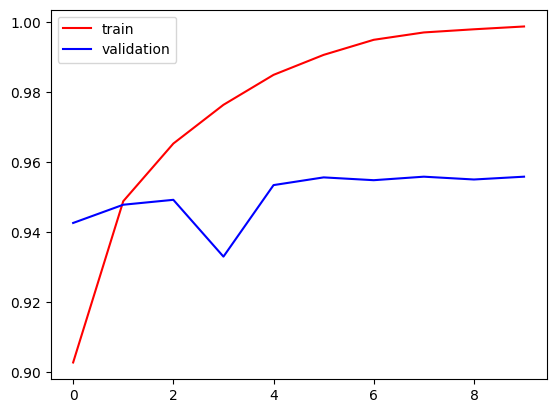

In [6]:
plt.plot(history.history["accuracy"], color="red", label="train")
plt.plot(history.history["val_accuracy"], color="blue", label="validation")
plt.legend()
plt.show()

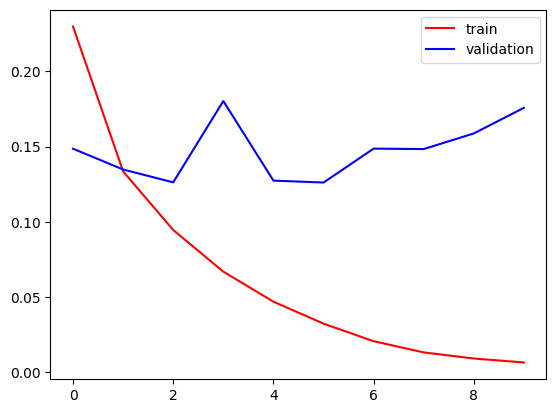

In [7]:
plt.plot(history.history["loss"], color="red", label="train")
plt.plot(history.history["val_loss"], color="blue", label="validation")
plt.legend()
plt.show()